# Shadow Zone Framing Model: checking the features, then the fit

Uses the full 2024 taken-pitch table if `data/processed/taken_2024.parquet` exists (run `shadow-zone prepare` first), otherwise the 2,286-pitch sample that ships with the package. The first cell prints which one ran.

In [1]:
import json
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from shadow_zone import calibration
from shadow_zone.data.sample import load_sample
from shadow_zone.model import FramingModel, DEFAULT_SCALES
from shadow_zone.effects import effect_table

path = Path('../data/processed/taken_2024.parquet')
d = pd.read_parquet(path) if path.exists() else load_sample()
print('using', 'full 2024 season' if path.exists() else 'packaged sample', '-', len(d), 'taken pitches')
d[['edge_dist', 'z_frac', 'strike']].describe().round(3)

using full 2024 season - 366825 taken pitches


,edge_dist,z_frac,strike
count,366825.000,366825.000,366825.000
mean,0.339,0.360,0.317
std,0.606,0.639,0.465
min,-0.829,-2.777,0.000
25%,-0.093,-0.092,0.000
50%,0.274,0.335,0.000
75%,0.693,0.809,1.000
max,4.642,3.562,1.000


## 1. Edge distance: does the feature mean what we think?

`edge_dist` is the signed distance in feet to the zone grown by one ball radius (negative inside). If it is built right, the called-strike rate should be near 1 well inside, near 0 well outside, and cross about half way near zero. The line below is a running average over pitches sorted by edge distance (no bins).

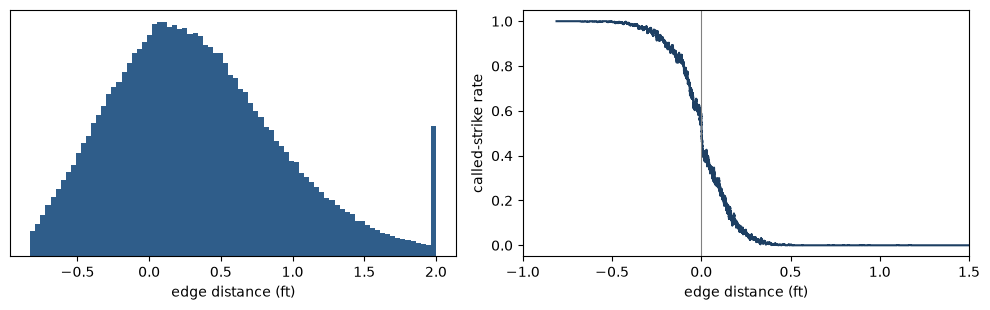

strike rate within 0.02 ft of the edge: 0.507 on 9827 pitches


In [2]:
s = d.sort_values('edge_dist')
win = max(200, len(s) // 400)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].hist(s['edge_dist'].clip(-1, 2), bins=80, color='#2f5d8a'); ax[0].set_xlabel('edge distance (ft)'); ax[0].set_yticks([])
ax[1].plot(s['edge_dist'], s['strike'].rolling(win, center=True).mean(), color='#1d3f63')
ax[1].axvline(0, color='grey', lw=0.8); ax[1].set_xlim(-1, 1.5)
ax[1].set_xlabel('edge distance (ft)'); ax[1].set_ylabel('called-strike rate')
fig.tight_layout(); plt.show()
near = s[s['edge_dist'].abs() <= 0.02]['strike']
print('strike rate within 0.02 ft of the edge:', round(near.mean(), 3), 'on', len(near), 'pitches')

Outliers and the zone itself. A pitch more than 3 feet from the zone, or a zone height that is not a human height, would be a data problem.

In [3]:
print('edge_dist range:', d['edge_dist'].min().round(2), 'to', d['edge_dist'].max().round(2))
print(d.groupby('stand')[['sz_top', 'sz_bot']].mean().round(2))
print(d['region'].value_counts(normalize=True).round(3))
print('mean plate_x, RHB minus LHB (catcher view; should be > 0):', round(d.loc[d['stand'] == 'R', 'plate_x'].mean() - d.loc[d['stand'] == 'L', 'plate_x'].mean(), 3))

edge_dist range: -0.83 to 4.64
       sz_top  sz_bot
stand                
L        3.40     1.6
R        3.41     1.6
region
outside    0.375
low        0.282
inside     0.173
high       0.170
Name: proportion, dtype: float64
mean plate_x, RHB minus LHB (catcher view; should be > 0): 0.593


## 2. Who is in the data

Effects for catchers and umpires with few pitches are shrunk hard toward zero; this shows how many pitches each one has.

In [4]:
print('catchers:', d['catcher'].nunique(), 'umpires:', d['umpire'].nunique(), 'games:', d['game_pk'].nunique())
print(d.groupby('catcher').size().describe().round(0))
print('share of taken pitches within 0.25 ft of the edge:', round((d['edge_dist'].abs() <= 0.25).mean(), 3))

catchers: 100 umpires: 90 games: 2429
count     100.0
mean     3668.0
std      2842.0
min         5.0
25%      1103.0
50%      3017.0
75%      5875.0
max      9431.0
dtype: float64
share of taken pitches within 0.25 ft of the edge: 0.322


## 3. Fit on half the games, check calibration on the other half

The README reports 2023 fit, 2024 scored. This is a quicker check in one season, splitting by game so that no game is in both halves.

all taken pitches  n= 183472  log loss 0.1532  calibration intercept -0.024 slope 0.996
shadow zone        n=  59008  log loss 0.4088  calibration intercept -0.033 slope 1.004


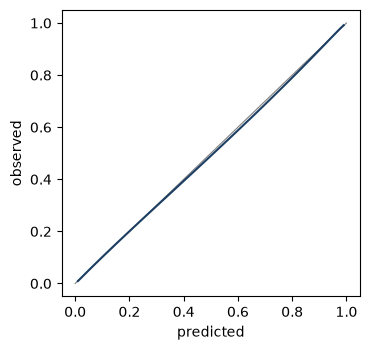

In [5]:
sp = Path('../reports/tables/scales.json')
scales = json.loads(sp.read_text()) if sp.exists() else DEFAULT_SCALES
train, test = d[d['game_pk'] % 2 == 0], d[d['game_pk'] % 2 == 1]
m = FramingModel(scales=scales).fit(train)
p = m.predict(test); y = test['strike'].to_numpy()
shadow = (test['edge_dist'].abs() <= 0.25).to_numpy()
for name, sel in [('all taken pitches', slice(None)), ('shadow zone', shadow)]:
    a, b = calibration.slope_intercept(y[sel], p[sel])
    print(f'{name:18s} n={len(y[sel]):7d}  log loss {calibration.log_loss_(y[sel], p[sel]):.4f}  calibration intercept {a:+.3f} slope {b:.3f}')
curve = calibration.smooth_calibration(y, p)
fig, ax = plt.subplots(figsize=(3.8, 3.6))
ax.plot([0, 1], [0, 1], color='grey', lw=0.8); ax.plot(curve['predicted'], curve['observed'], color='#1d3f63')
ax.set_xlabel('predicted'); ax.set_ylabel('observed'); fig.tight_layout(); plt.show()

## 4. Catcher effects from the fit on all games

`effect_logit` is relative to an average catcher; `edge_pp` is the change in called-strike probability on shadow-zone pitches. With the full season there are 77 catchers with 1,000+ taken pitches; on the sample every catcher has few pitches, so intervals are wide and the ranking means little.

In [6]:
m_all = FramingModel(scales=scales).fit(d)
tbl = effect_table(m_all, d, 'catcher')
tbl = tbl[tbl['pitches'] >= (1000 if path.exists() else 100)]
cols = ['catcher', 'pitches', 'effect_logit', 'se', 'edge_pp', 'edge_pp_lo95', 'edge_pp_hi95']
print(pd.concat([tbl.head(5), tbl.tail(5)])[cols].round(2).to_string(index=False))

 catcher  pitches  effect_logit   se  edge_pp  edge_pp_lo95  edge_pp_hi95
  624431     5069          0.40 0.08     5.14          3.15          7.14
  672275     8112          0.38 0.07     4.93          3.23          6.64
  595978     3431          0.33 0.08     4.34          2.18          6.50
  668670     5991          0.32 0.08     4.16          2.23          6.09
  543877     6033          0.31 0.07     4.05          2.18          5.92
  642136     2926         -0.25 0.09    -3.18         -5.45         -0.91
  553882     1751         -0.28 0.10    -3.62         -6.25         -0.98
  571466     2031         -0.28 0.10    -3.66         -6.18         -1.13
  543228     2075         -0.34 0.10    -4.41         -7.01         -1.81
  641598     1514         -0.43 0.12    -5.57         -8.47         -2.67


Ids are shown because the export has no catcher names; the CLI run joins names from the MLB StatsAPI and writes `reports/tables/catcher_effects_*.csv`.